In [ ]:
ALLOW_DOWNLOADS = False

def download_with_permission(operation, *args, **kwargs):
    if not ALLOW_DOWNLOADS:
        raise RuntimeError("Для загрузки ресурсов установите ALLOW_DOWNLOADS = True; пути к данным описаны в INPUTS.md.")
    return operation(*args, **kwargs)


# 

# Машинное обучение. ВМК МГУ

# Практическое задание 7: SVM
## Уровень: <font color='SkyBlue'>**Базовый (Base)**</font>

# О формате сдачи

🔷 **<font color='plum'>При решении ноутбука используйте данный шаблон</font>**

    ✅ Можно добавлять новые ячейки любых типов
    ❌ Не нужно удалять текстовые ячейки c разметкой частей ноутбука и формулировками заданий


🔷 **<font color='plum'>При оценивании задач учитывается код</font>**

    ✅ Задания, в которых необходим код, обычно помечаются фразами "Your code here"/"Ваш код" и аналогичными
    ❌ Ответы на вопросы без сопутствующего кода оцениваются в 0 баллов
    ❌ Наличе работоспособного кода в ноутбуке, если на сказано иного, обязательно

🔷 **<font color='plum'>При оценивании задач учитываются выводы</font>**

    ✅ Задания, в которых необходимы выводы, обычно помечаются фразами Вывод"/"Ответ на вопрос"/"Ваш текст" и аналогичными
    ✅ Обычно выводы подразумевают под собой текстовый ответ (можно писать markdown, latex).
    ✅ Сопутствующие изображения, графики, таблички - приветствуются!
    ❌ При отсутствии выводов задание не засчитается на полный балл

Цель данного задания:

* Изучите работу модели SVM
* Поймете, как с её помощью можно строить нелинейные разделяющие поверхности
* Потренируетесь в подборе оптимальных параметров на обучающей выборке для достижения наилучшего качества на закрытой выборке (ML-решение)

-------
<font color="white" style="opacity:0.2025"></font>
<font color=DarkOrange>**Примерное время выполнения (execution time/время выполнения, если нажать run all) всех ячеек ноутбука при правильной реализации: до 10 минут </font>**

# Подготовка рабочей среды

Сначала установим нужные нам версии библиотек. Мы гарантируем, что в данных версиях задание будет корректно отрабатывать.

После установки нужных версий, **возможно,** нужно перезагрузить среду (runtime), но скорее всего вам это не понадобится


На скачивание файла и установку понадобится не более 5 минут.

<font color='OrangeRed'>**Важно!**</font>

Устанавливать нужные версии нужно каждый раз, когда создается новый рантайм. Например, если вы 2 часа подряд делаете это задание, то подготовить библиотеки достаточно 1 раз. Но если вы, например, начали в понедельник, затем закрыли/выключили ноутбук, то при продолжении в среду, вам нужно будет запустить рантайм заново и следовательно заново установить библиотеки.

<font color='OrangeRed'>**Важно!**</font>
Если вы предпочитаете делать практические задания на своем личном ноутбуке, то проверьте, что вы установили рабочее окружение в [соответствии с гайдом](https://github.com/MSU-ML-COURSE/ML-COURSE-24-25/blob/main/tutorials/%D0%A2%D1%83%D1%82%D0%BE%D1%80%D0%B8%D0%B0%D0%BB%20%D0%BF%D0%BE%20%D1%83%D1%81%D1%82%D0%B0%D0%BD%D0%BE%D0%B2%D0%BA%D0%B5%20%D1%80%D0%B0%D0%B1%D0%BE%D1%87%D0%B5%D0%B3%D0%BE%20%D0%BE%D0%BA%D1%80%D1%83%D0%B6%D0%B5%D0%BD%D0%B8%D1%8F%20%D0%B2%20Python%20%D0%B4%D0%BB%D1%8F%20%D1%80%D0%B5%D1%88%D0%B5%D0%BD%D0%B8%D1%8F%20%D0%B7%D0%B0%D0%B4%D0%B0%D1%87%20(2).pdf)


In [ ]:
# Установка зависимостей выполняется отдельно по requirements.txt.
# Установка зависимостей выполняется отдельно по requirements.txt.


Проверим версию библиотеки:

In [ ]:
import catboost
assert(catboost.__version__ == '1.2.8')

Теперь можно приступать к выполнению задания! :)

-----------
<font color="white" style="opacity:0.2025"></font>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

from copy import copy

Если Вы дальтоник, то можете воспользоваться готовой colormap из matplotlib (или найти свою):
```
plt.style.use('tableau-colorblind10')
```

Приведем вспомогательный код

In [ ]:
from matplotlib.colors import ListedColormap

from sklearn.svm import LinearSVC, SVC
from sklearn.decomposition import PCA
from sklearn.model_selection import cross_val_score, cross_val_predict, cross_validate, train_test_split
from sklearn.metrics import make_scorer, accuracy_score, roc_auc_score
from sklearn.datasets import make_blobs, make_circles, make_moons

In [ ]:
def make_moons_cls(size=1000, d=2):
    X, y = make_moons(n_samples=size, noise=0.15)
    if d > 2:
        X = np.concatenate((X, np.random.normal(size=(size, d-2))), axis=1)
    return X, y

def make_circles_cls():
    X, y = make_circles()

def generate_data_with_imb_classes(size1=100, size2=10):
    X = np.r_[(
        np.random.normal(loc=1.0, size=(size1, 2)),
        np.random.normal(loc=0.5, size=(size2, 2))
    )]

    y = np.ones(len(X))
    y[-size2:] = 0
    return X, y

In [ ]:
def plot_separating_surface(X, y, cls, view_support=False, title=''):
    x_min = min(X[:, 0]) - 0.1
    x_max = max(X[:, 0]) + 0.1
    y_min = min(X[:, 1]) - 0.1
    y_max = max(X[:, 1]) + 0.1
    h = 0.005
    cm = plt.cm.RdBu
    cm_bright = ListedColormap(['#FF0000', '#0000FF'])

    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                             np.arange(y_min, y_max, h))
    Z = cls.predict(np.c_[xx.ravel(), yy.ravel()])

    plt.figure(figsize=(10, 10))
    if title:
        plt.title(title)
    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', s=40, cmap=cm_bright)
    if view_support:
        plt.scatter(X[cls.support_, 0], X[cls.support_, 1],
                    c=y[cls.support_], edgecolors='k', s=150, cmap=cm_bright)
    Z = Z.reshape(xx.shape)
    plt.xticks(())
    plt.yticks(())
    plt.contourf(xx, yy, Z, cmap=cm, alpha=.3)
    plt.show()

# Загрузка данных

In [ ]:
import gdown
download_with_permission(gdown.download_folder, 'https://drive.google.com/drive/folders/1bp39_Jj0edo1lzxZ3DIoChsOVy5DVi1R?usp=sharing')

# SVM и разделяющая поверхность

На лекции вы изучили, что линейная, с виду, модель SVM, при помощи некоторых "фокусов", называемых ядрами, умеет строить нелинейные поверхности. В данном ноутбуке посмотрим, как это все работает на практике, и какие гиперпараметры настройки у этого метода есть.

<font color='MediumTurquoise'>**Историческая справка:**</font> Метод опорных векторов (SVM) стал популярным в 90-х годах, особенно с 1995 года, благодаря своей эффективности в задачах классификации и способности обрабатывать высокоразмерные данные. Он также привлек внимание благодаря использованию ядровых функций, что позволяло решать нелинейные задачи. Однако с появлением более сложных методов, таких как глубокое обучение, и увеличением объема данных, SVM стал менее популярным, поскольку более современные алгоритмы демонстрировали лучшие результаты на больших наборах данных и обеспечивали более простую настройку.

## <font color='DarkOrange'>**Задание 1 [1 балл]**</font>


В ячейке ниже генерируется выборка, состоящая из объектов двух классов. Каждый объект представлен двумя координатами, так что объекты этой выборки можно отобразить на плоскости, используя функцию scatter из библиотеки matplotlib.


    
В этом задании вам надо будет обучить линейную разделяющую поверхность с помощью ```sklearn.svm.SVC(kernel='linear')```, а также нелинейную c rbf-ядром с помощью ```sklearn.svm.SVC(kernel='rbf')```. Остальные параметры методов можете оставить дефолтными. Делить выборку на обучение и валидацию сейчас не требуется, так как нас будет пока интересовать только форма разделяющей кривой.

In [ ]:
X, y = make_moons_cls()
linear_svc = SVC(kernel='linear')
nonlinear_svc = SVC(kernel='rbf')

Визуализируем выборку

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(X[y == 0, 0], X[y == 0, 1], label='y=0')
plt.scatter(X[y == 1, 0], X[y == 1, 1], label='y=1')
plt.xlabel('$x_0$')
plt.ylabel('$x_1$')
plt.legend()
plt.grid()

Обучите модели и визуализируйте разделяющую поверхность для обеих моделей с помощью функции plot_separating_surface(). Посчитайте точность (accuracy) на обучающей выборке для каждой из моделей.

In [ ]:
# Your code here
linear_svc.fit(X, y)
plot_separating_surface(X, y, linear_svc, view_support=False, title='Linear SVM Decision Boundary')

print(f'Train Accuracy (linear): {accuracy_score(y, linear_svc.predict(X)):.3f}')

In [ ]:
# Your code here
nonlinear_svc.fit(X, y)
plot_separating_surface(X, y, nonlinear_svc, view_support=False, title='RBF SVM Decision Boundary')

print(f'Train Accuracy (non linear): {accuracy_score(y, nonlinear_svc.predict(X)):.3f}')

**Сделайте вывод**
о получившихся результатах. Какая из моделей лучше подходит для данной выборки и почему?

<font color='MediumOrchid'>**Ваши выводы тут:**</font>

Линейная SVM показывает границу в виде линии (правда неожиданно 0_о), а RBF SVM - сложную в виде инь-яня в квадрате.

Существенное различие в точности (0.1) явно указывает на преимущество нелинейной модели для данной задачи, что объясняется сложной, криволинейной структурой данных, которую невозможно адекватно разделить с помощью линейной функции.

## 2. Опорные объекты

Продолжаем работать с выборкой и моделями из первой части. Для линейной и rbf-моделей рассмотрим
    опорные объекты, полученные после обучения. Визуализировать их можно, используя функуцию plot_separating_surface с параметром vis_support=True. Достанем опорные объекты из обученной модели с помощью поля model.support_.

In [ ]:
plot_separating_surface(X, y, nonlinear_svc, view_support=True)

Обучим новые две модели ```SVC(kernel='rbf')```, используя только опорные объекты построенные с помощью соответственно линейной (linear_svc) и нелинейной (nonlinear_svc) моделей из первой части.

In [ ]:
# Учим модели только на опорных объектах
svc_on_linear_support = SVC(kernel='rbf').fit(X[linear_svc.support_, :], y[linear_svc.support_])
svc_on_rbf_support = SVC(kernel='rbf').fit(X[nonlinear_svc.support_, :], y[nonlinear_svc.support_])

In [ ]:
plot_separating_surface(X, y, svc_on_linear_support)

In [ ]:
plot_separating_surface(X, y, svc_on_rbf_support)

### <font color='DarkOrange'>**Задание 2 [1 балл]**</font>

Сравните полученные разделяющие поверхности с нелинейной моделью (nonlinear_svc) из задания 1. Какая из поверхностей больше похожа на нелинейнную модель из первой части и почему, опишите в выводе.


<font color='MediumOrchid'>**Ваши выводы тут:**</font>

Поверхность по RBF-опорным векторам почти повторяет исходную сложную границу, в отличие от версии по линейным. Так происходит потому, что опорные векторы — это «контрольные точки» на границе классов. В нелинейном случае модель выбирает именно те точки, которые лучше всего очерчивают форму разделяющей плоскости.

---

Теперь обучим модель ```SVC(kernel='rbf')```, используя все объекты кроме тех, что являлись опорными для нелинейной модели из первой части (nonlinear_svc) и сравним эту модель вместе с svc_on_rbf_support с нелинейной моделью из задания 1(nonlinear_svc). Визуализируйте разделяющие поверхности обеих моделей.

In [ ]:
non_support_vectors = [i for i in range(len(X)) if i not in nonlinear_svc.support_]
svc_all_without_rbf_support = SVC(kernel='rbf').fit(X[non_support_vectors, :], y[non_support_vectors])

In [ ]:
plot_separating_surface(X, y, svc_all_without_rbf_support)

In [ ]:
plot_separating_surface(X, y, nonlinear_svc)

In [ ]:
plot_separating_surface(X, y, svc_on_rbf_support)

### <font color='DarkOrange'>**Задание 3 [1.5 баллa]**</font>

**Сделайте вывод:** Сильно ли полученные поверхности отличаются от той, что была получена в первом задании? Что произошло с пограничными объектами? Объясните полученные результаты.

<font color='MediumOrchid'>**Ваши выводы тут:**</font>

Поверхности практически не отличаются. После удаления исходных пограничных объектов модель нашла новые опорные векторы среди оставшихся данных, которые продолжили определять границу.
Это возможно потому, что информация о форме содержится в глобальных закономерностях размещения точек. RBF-ядро, улавливая эти закономерности, реконструировало границу, опираясь на новую, но не менее информативную выборку опорных наблюдений.

# 4. Обучите лучшую SVM модель (ML-решение)

Возможность строить нелинейные поверхности может сильно улучшить качество, но и несет риск переобучения.
    В этом задании предстоит обучить лучшую svm модель и получить хорошее качество на тесте в системе тестирования. Для контроля переобучения рекомендуется пользоваться кросс-валидацией. Для улучшения качества рекомендуется подбирать

1. параметр регуляризации C;
2. тип разделяющей кривой linear/rbf/poly;
3. степень в случае разделяющей кривой poly.

Также не забывайте, что при решении задач машинного обучения полезно смотреть в данные :)

Все csv-таблицы с данными вы можете взять из публичного теста, который также есть в проверяющей системе. Для этого распакуйте архив с публичными тестами и положите файлы в рабочей директории (рядом с ноутбуком)

In [ ]:
X_train = np.load('05-SVM/public/cX_train.npy')
y_train = np.load('05-SVM/public/cy_train.npy')
X_test = np.load('05-SVM/public/cX_test.npy')

In [ ]:
X_train.shape, y_train.shape, X_test.shape

In [ ]:
X = X_train
y = y_train.ravel()

In [ ]:
plt.scatter(X[y == 0, 4], X[y == 0, 3], label='y=0')
plt.scatter(X[y == 1, 4], X[y == 1, 3], label='y=1')
plt.legend()

**Отправьте код обучения модели с оптимальными параметрами в проверяющую систему, воспользовавшись приложенным шаблоном svm_solution.py. Кросс-валидацию параметров в посылаемом решении делать <font color='red'>не нужно</font> -- достаточно подобрать, например, их тут, а в решении уже обучать модель с оптимальными параметрами.**

In [ ]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
import pandas as pd

X_train_saved = X_train
X_test_saved = X_test

X_train = [[x[3], x[4]] for x in X_train]
X_test = [[x[3], x[4]] for x in X_test]


param_grid = [
    {'C': [0.01, 0.1, 1, 10, 100], 'kernel': ['linear']},
    {'C': [0.01, 0.1, 1, 10, 100], 'kernel': ['rbf'], 'gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1]},
    {'C': [0.01, 0.1, 1, 10, 100], 'kernel': ['poly'], 'degree': [2, 3, 4, 5], 'gamma': ['scale', 'auto']}
]

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True)
grid_search = GridSearchCV(SVC(), param_grid, cv=cv_strategy, scoring='accuracy', n_jobs=-1, verbose=1)
grid_search.fit(X_train, y_train)

print(f"Лучшие параметры: {grid_search.best_params_}")
print(f"Лучшая точность на кросс-валидации: {grid_search.best_score_:.4f}")

best_model = grid_search.best_estimator_
best_model.fit(X_train, y_train)

y_train_pred = best_model.predict(X_train)
train_accuracy = accuracy_score(y_train, y_train_pred)
print(f"Точность на тренировочных данных: {train_accuracy:.4f}")



svm_results = pd.DataFrame(grid_search.cv_results_)
svm_results_sorted = svm_results.sort_values('mean_test_score', ascending=False)

print("\nРезультаты кросс-валидации для всех моделей SVM:")
print("="*80)

svm_summary = []
for i, row in svm_results_sorted.iterrows():
    summary = {
        'C': row['param_C'],
        'Kernel': row['param_kernel'],
        'CV Accuracy': f"{row['mean_test_score']:.4f}",
        'Std Dev': f"{row['std_test_score']:.4f}",
        'Rank': row['rank_test_score']
    }

    # Добавляем параметры ядра
    if 'param_gamma' in row:
        summary['Gamma'] = row['param_gamma']
    if 'param_degree' in row:
        summary['Degree'] = row['param_degree']

    svm_summary.append(summary)

svm_df = pd.DataFrame(svm_summary)
print(svm_df.head(20))

# Сравнение с логистической регрессией

#### <font color='DarkOrange'>**Задание 4 [1.5 баллa]**</font>

В предыдущей части Вы обучили хорошую SVM модель, подбирая гиперпараметры модели. Давайте теперь попробуем обучить логистическую регрессию на этой же выборке, и по кросс-валидации оценить влияние гиперпараметров на линейную модель.

In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
# Your code here
param_grid_lr = [
    {
        'C': [0.001, 0.01, 0.1, 1, 10, 100],
        'penalty': ['l1', 'l2'],
        'solver': ['liblinear', 'saga']
    },
    {
        'C': [0.001, 0.01, 0.1, 1, 10, 100],
        'penalty': ['elasticnet'],
        'solver': ['saga'],
        'l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]
    },
    {
        'C': [0.001, 0.01, 0.1, 1, 10, 100],
        'penalty': [None],
        'solver': ['lbfgs', 'newton-cg']
    }
]

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True)
grid_search_lr = GridSearchCV(
    LogisticRegression(class_weight='balanced'),
    param_grid_lr,
    cv=cv_strategy,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)
grid_search_lr.fit(X_train, y_train)

print(f"Лучшие параметры: {grid_search_lr.best_params_}")
print(f"Лучшая точность на кросс-валидации: {grid_search_lr.best_score_:.4f}")

best_lr_model = grid_search_lr.best_estimator_
best_lr_model.fit(X_train, y_train)

y_train_pred_lr = best_lr_model.predict(X_train)
train_accuracy_lr = accuracy_score(y_train, y_train_pred_lr)
print(f"Точность на тренировочных данных: {train_accuracy_lr:.4f}")



cv_results = pd.DataFrame(grid_search_lr.cv_results_)
cv_results_sorted = cv_results.sort_values('mean_test_score', ascending=False)

print("Результаты кросс-валидации для всех моделей логистической регрессии:")
print("="*80)

columns_to_show = [
    'param_C', 'param_penalty', 'param_solver',
    'mean_test_score', 'std_test_score',
    'mean_fit_time', 'params', 'l1_ratio'
]

results_summary = []
for i, row in cv_results_sorted.iterrows():
    results_summary.append({
        'C': row['param_C'],
        'Penalty': row['param_penalty'],
        'Solver': row['param_solver'] if 'param_solver' in row else 'default',
        'L1 ratio': row['param_l1_ratio'] if 'param_l1_ratio' in row else 'None',
        'CV Accuracy': f"{row['mean_test_score']:.4f}",
        'Std Dev': f"{row['std_test_score']:.4f}",
        'Rank': row['rank_test_score']
    })

results_df = pd.DataFrame(results_summary)
print(results_df.head(20))

Сделайте выводы о влиянии выбора гиперпараметров на качество обучения линейной и SVC моделей. Также опишите, какие преобразования выборки/подбор каких гиперпараметров помогли добиться высокого качества на кросс-валидации в данной задаче.

<font color='MediumOrchid'>**Ваши выводы тут:**</font>

Настройка линейной модели критически зависит от C, solver и penalty, тогда как для SVC главную роль играет kernel, а также gamma и C.
В этом эксперименте оптимальные результаты были достигнуты благодаря:

1) Подбору гиперпараметров C, penalty и solver.

2) Выбору наиболее значимых признаков — № 3 и № 4.

### <font color='MediumSeaGreen'>**Задание 5 [1 балл][Bonus]**</font>

Найдите мем про SVM лучше чем этот:

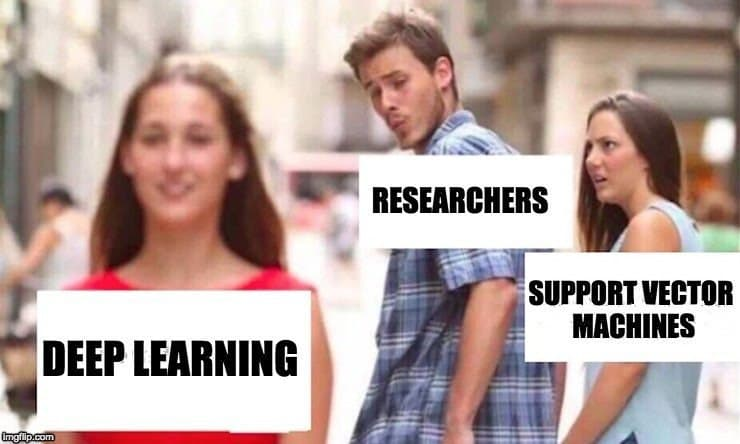

Важно: самый простой способ вставить картинку будет через Google Colab (даже если вы изначально делали не в нем). Нажмите на **"+ Text"**, в появившейся ячейке сделайте **прикрепление картинки** (как на скринах). Тогда ваша картинка "зашифруется" и будет корректно отображаться при конвертации в html

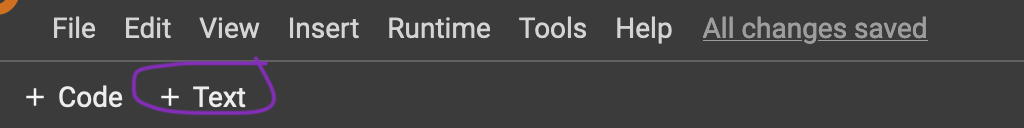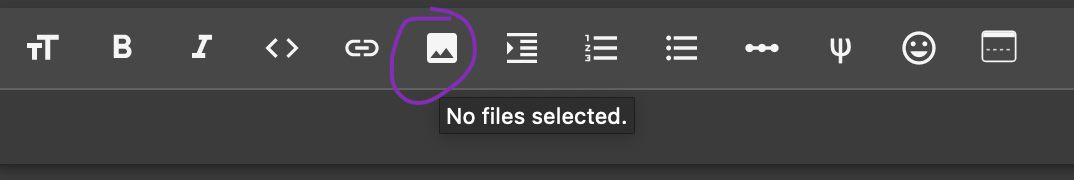

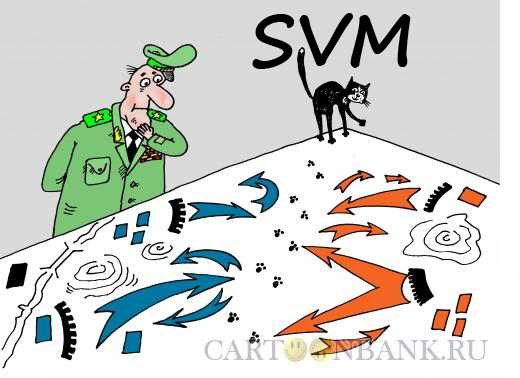